# Hierarchical clustering of 500 homes (Hai)

What this notebook does, in 3 lines:
- Builds 4 features per home (AC, Heater, Fridge, Other)
- Runs Ward hierarchical clustering and tests it against shuffled data
- Result: no strong clusters, so we make usage tiers instead

Input: Data/raw/smart_home_energy_consumption_large.csv
Output: home_tiers.csv

## Section 1: Import libraries and Data Handling

In [1]:
# Data Handling
import pandas as pd
import numpy as np

# Plotting
import matplotlib.pyplot as plt

# Clustering and the tree (SciPy)
from scipy.cluster.hierarchy import dendrogram, linkage, cophenet, fcluster
from scipy.spatial.distance import pdist

# Scoring (scikit-learn)
from sklearn.metrics import silhouette_score

df = pd.read_csv('../../Data/raw/smart_home_energy_consumption_large.csv')
print(df.shape)
print(df.columns)
print(df.head(10))

(100000, 8)
Index(['Home ID', 'Appliance Type', 'Energy Consumption (kWh)', 'Time', 'Date',
       'Outdoor Temperature (°C)', 'Season', 'Household Size'],
      dtype='str')
   Home ID    Appliance Type  Energy Consumption (kWh)   Time        Date  \
0       94            Fridge                      0.20  21:12  2023-12-02   
1      435              Oven                      0.23  20:11  2023-08-06   
2      466        Dishwasher                      0.32  06:39  2023-11-21   
3      496            Heater                      3.92  21:56  2023-01-21   
4      137         Microwave                      0.44  04:31  2023-08-26   
5       68  Air Conditioning                      4.68  11:36  2023-05-06   
6      237          Computer                      0.25  12:05  2023-06-06   
7      329  Air Conditioning                      3.50  03:34  2023-12-12   
8      336        Dishwasher                      0.89  15:22  2023-08-16   
9      310         Microwave                      1.34 

## Section 2. Data quality checks
### 2a. Wrong types, missing values or duplicates

In [2]:
df.info()
print(df.isna().sum())
print(f"Duplicate rows: {df.duplicated().sum()}")

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 8 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   Home ID                   100000 non-null  int64  
 1   Appliance Type            100000 non-null  str    
 2   Energy Consumption (kWh)  100000 non-null  float64
 3   Time                      100000 non-null  str    
 4   Date                      100000 non-null  str    
 5   Outdoor Temperature (°C)  100000 non-null  float64
 6   Season                    100000 non-null  str    
 7   Household Size            100000 non-null  int64  
dtypes: float64(2), int64(2), str(4)
memory usage: 6.1 MB
Home ID                     0
Appliance Type              0
Energy Consumption (kWh)    0
Time                        0
Date                        0
Outdoor Temperature (°C)    0
Season                      0
Household Size              0
dtype: int64
Duplicate rows: 0


### 2b Dates cover, min and max

In [3]:
df["Date"] = pd.to_datetime(df["Date"])
print(f"First date: {df['Date'].min()}")
print(f"Last date: {df['Date'].max()}")


First date: 2023-01-01 00:00:00
Last date: 2024-01-01 00:00:00


### 2c Homes and reading per each home

In [4]:
#  how many homes, and how many readings does each home have?
print("Number of homes:", df["Home ID"].nunique())
home_counts = df["Home ID"].value_counts()
print("Readings per home: min", home_counts.min(), "max", home_counts.max())

#  which appliance types are there, and how many readings each?
print("Number of appliance types:", df["Appliance Type"].nunique())
print(df["Appliance Type"].value_counts())
# Finding: 500 homes, 10 appliance types, each with about 10,000 readings, 157 to 245 readings per home

Number of homes: 500
Readings per home: min 157 max 245
Number of appliance types: 10
Appliance Type
Lights              10201
Dishwasher          10095
Air Conditioning    10067
Heater              10018
Washing Machine      9953
Microwave            9947
Computer             9944
Oven                 9939
Fridge               9931
TV                   9905
Name: count, dtype: int64


### 2d Data Describe

In [5]:
df[["Energy Consumption (kWh)", "Outdoor Temperature (°C)", "Household Size"]].describe()

,Energy Consumption (kWh),Outdoor Temperature (°C),Household Size
count,100000.000000,100000.000000,100000.000000
mean,1.499952,14.950135,3.001770
std,1.181176,14.438755,1.417077
min,0.100000,-10.000000,1.000000
25%,0.590000,2.400000,2.000000
50%,1.230000,14.900000,3.000000
75%,1.870000,27.400000,4.000000
max,5.000000,40.000000,5.000000


## Section 3. What drives energy use?

### 3a. Does energy differ by appliance type and season?
 Finding: AC and Heater about 3.5 kWh, Fridge 0.3, the rest about 1.1; seasons all about 1.5

In [6]:
print(df.groupby("Appliance Type")["Energy Consumption (kWh)"].mean())
print(df.groupby("Season")["Energy Consumption (kWh)"].mean())


Appliance Type
Air Conditioning    3.499857
Computer            1.095498
Dishwasher          1.103369
Fridge              0.298255
Heater              3.486802
Lights              1.087356
Microwave           1.100961
Oven                1.103080
TV                  1.097221
Washing Machine     1.101412
Name: Energy Consumption (kWh), dtype: float64
Season
Fall      1.497545
Spring    1.510863
Summer    1.495173
Winter    1.496156
Name: Energy Consumption (kWh), dtype: float64


### 3b. Does energy differ by household size?
Finding: all sizes about 1.5

In [7]:
print(df.groupby("Household Size")["Energy Consumption (kWh)"].mean())

Household Size
1    1.507659
2    1.513151
3    1.490346
4    1.503494
5    1.485319
Name: Energy Consumption (kWh), dtype: float64


### 3c. Do homes differ from each other?
Finding: home averages run from 1.28 to 1.75, std about 0.08

In [8]:
home_avg = df.groupby("Home ID")["Energy Consumption (kWh)"].mean()
print(home_avg.min())
print(home_avg.max())
print(home_avg.std())

1.2779428571428573
1.7549197860962569
0.07986795115802153


### 3d. Does season change energy inside each appliance?
Finding: no, each appliance is about the same in every season

In [9]:

print(df.groupby(["Appliance Type", "Season"])["Energy Consumption (kWh)"].mean())

Appliance Type    Season
Air Conditioning  Fall      3.467990
                  Spring    3.526081
                  Summer    3.487953
                  Winter    3.517397
Computer          Fall      1.099683
                  Spring    1.106818
                  Summer    1.082650
                  Winter    1.092364
Dishwasher        Fall      1.105914
                  Spring    1.097696
                  Summer    1.103786
                  Winter    1.106026
Fridge            Fall      0.298662
                  Spring    0.296985
                  Summer    0.297852
                  Winter    0.299526
Heater            Fall      3.477411
                  Spring    3.483162
                  Summer    3.513151
                  Winter    3.473078
Lights            Fall      1.081804
                  Spring    1.090336
                  Summer    1.100091
                  Winter    1.077435
Microwave         Fall      1.112808
                  Spring    1.116443
             

### 3e. Correlations, household size per home, readings per pair
Finding: correlations about 0, every home has all 5 sizes, about 20 readings per home-appliance pair (5 to 41)

In [10]:
print(df["Energy Consumption (kWh)"].corr(df["Household Size"]))
print(df["Energy Consumption (kWh)"].corr(df["Outdoor Temperature (°C)"]))
size_per_home = df.groupby("Home ID")["Household Size"].nunique()
print(size_per_home.describe())
reading_per_pair = df.groupby(["Home ID", "Appliance Type"]).size()
print(reading_per_pair.describe())

-0.006501441329598255
0.0019946336406094513
count    500.0
mean       5.0
std        0.0
min        5.0
25%        5.0
50%        5.0
75%        5.0
max        5.0
Name: Household Size, dtype: float64
count    5000.000000
mean       20.000000
std         4.457261
min         5.000000
25%        17.000000
50%        20.000000
75%        23.000000
max        41.000000
dtype: float64


## Section 4, build the 4 features
### 4a. Group the appliances
Group the 7 smaller appliances into 'Other'
Findings: Other 69,984 readings; AC 10,067; Heater 10,018; Fridge 9,931; none missing

In [11]:
df['Group'] = df['Appliance Type'].map({
    'Air Conditioning': 'Air Conditioning',
    'Heater': 'Heater',
    'Fridge': 'Fridge',
    'Computer' : 'Other',
    'Washing Machine' : 'Other',
    'Dishwasher' : 'Other',
    'Microwave' : 'Other',
    'Oven' : 'Other',
    'TV' : 'Other',
    'Lights' : 'Other',})
print(df['Group'].value_counts())
print(df["Group"].isna().sum())



Group
Other               69984
Air Conditioning    10067
Heater              10018
Fridge               9931
Name: count, dtype: int64
0


### 4b. Average kWh per home and group
Findings: 500 homes by 4 features
Average, not total, because homes have different numbers of readings

In [12]:
home_features = df.groupby(['Home ID', 'Group'])['Energy Consumption (kWh)'].mean().unstack()
print(home_features.head())
print(home_features.shape)

Group    Air Conditioning    Fridge    Heater     Other
Home ID                                                
1                3.378261  0.274000  3.467727  1.132123
2                3.341765  0.301765  3.221200  1.127000
3                3.652500  0.318500  3.826667  1.111484
4                3.365000  0.351053  3.242778  1.058699
5                3.585789  0.340000  3.278636  1.067319
(500, 4)


### 4c. Check the features
Finding: means AC 3.50, Heater 3.49, Fridge 0.30, Other 1.10; no missing values; std about 0.19, 0.20, 0.025 and 0.046

In [13]:

print(home_features.describe())
print(home_features.isna().sum())

Group  Air Conditioning      Fridge      Heater       Other
count        500.000000  500.000000  500.000000  500.000000
mean           3.497888    0.298659    3.489674    1.097945
std            0.187825    0.025384    0.200351    0.045666
min            2.785000    0.228667    2.800833    0.956015
25%            3.367062    0.280929    3.362024    1.063682
50%            3.508608    0.297997    3.487684    1.100484
75%            3.630096    0.316977    3.630602    1.131825
max            4.005882    0.367647    4.076154    1.222038
Group
Air Conditioning    0
Fridge              0
Heater              0
Other               0
dtype: int64


## 5. Scale
Findings: z-score every column has mean about 0 and std 1 (the e-15 values are rounding, so zero)

In [14]:
scaled = (home_features - home_features.mean()) / home_features.std()
print(scaled.shape)
print(scaled.std())
print(scaled.mean())


(500, 4)
Group
Air Conditioning    1.0
Fridge              1.0
Heater              1.0
Other               1.0
dtype: float64
Group
Air Conditioning   -1.513456e-15
Fridge             -1.551825e-14
Heater              5.055512e-15
Other               7.339906e-15
dtype: float64


### 6a. Ward tree
Findings: The last joins are 13.8, 15.2, 18.2, 21.5, 23.2, growing smoothly; the final join merges 186 and 314 homes

In [15]:
Z = linkage(scaled, method='ward')
print(Z.shape)
print(Z[-5:])


(499, 4)
[[988.         991.          13.82801701 154.        ]
 [990.         992.          15.23154948 160.        ]
 [989.         993.          18.16440784 186.        ]
 [994.         995.          21.50788881 314.        ]
 [996.         997.          23.15787699 500.        ]]


### 6b. Dendrogram
Findings: Smooth pyramid, no tall empty gap, so no obvious natural split.

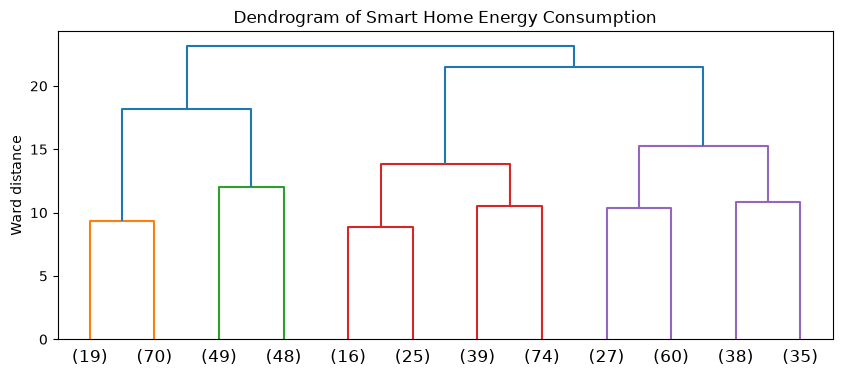

In [16]:
plt.figure(figsize=(10, 4))
dendrogram(Z, truncate_mode='lastp', p=12)
plt.title('Dendrogram of Smart Home Energy Consumption')
plt.ylabel('Ward distance')
plt.show()

### 6c. Cophenetic
Findings : 0.375, so the tree is a weak summary of the distances

In [17]:

c, _ = cophenet(Z, pdist(scaled))
print(c)

0.375163290595753


## 7. Silhouette
Findings : 0.134, 0.133, 0.13, 0.131, 0.135: flat and below 0.25

In [18]:


for k in range(2, 7):
    labels = fcluster(Z, t=k, criterion='maxclust')
    score = silhouette_score(scaled, labels)
    print(k, round(score, 3))

2 0.134
3 0.133
4 0.13
5 0.131
6 0.135


### 8a. Shuffle, seed 42
a fixed seed, any whole number
Findings: Shuffled scores are about the same as real (0.147, 0.125, 0.126, 0.124, 0.128)

In [19]:


rng = np.random.default_rng(42)       # a fixed seed, any whole number
shuffled = scaled.copy()
for col in shuffled.columns:
    shuffled[col] = rng.permutation(shuffled[col].values)

print(shuffled.shape)
print(shuffled.mean())

Z_shuf = linkage(shuffled, method='ward')
print(Z_shuf.shape)
print(Z_shuf[-5:])

for k in range(2, 7):
    labels = fcluster(Z_shuf, t=k, criterion='maxclust')
    score = silhouette_score(shuffled, labels)
    print(k, round(score, 3))



(500, 4)
Group
Air Conditioning   -1.518785e-15
Fridge             -1.553246e-14
Heater              5.041301e-15
Other               7.354117e-15
dtype: float64
(499, 4)
[[988.         989.          15.01024449 156.        ]
 [982.         991.          15.30511716 110.        ]
 [992.         995.          17.77092782 242.        ]
 [993.         994.          18.98496409 258.        ]
 [996.         997.          24.28895996 500.        ]]
2 0.147
3 0.125
4 0.126
5 0.124
6 0.128


### 8b. Fixed seed so the shuffle is the same every time and 20 different shuffles (seeds 0 to 19)
Shuffled min 0.113, mean 0.131, max 0.146; real 0.133 is inside the range

In [20]:
scores = []
for seed in range(20):                       # how many shuffles: use 20
    rng = np.random.default_rng(seed)          # use the loop variable `seed`
    sh = scaled.copy()

    for col in sh.columns:
        sh[col] = rng.permutation(sh[col].values)

    Zs = linkage(sh, method='ward')
    labels = fcluster(Zs, t=3, criterion='maxclust')
    scores.append(silhouette_score(sh, labels))

print(round(min(scores), 3), round(np.mean(scores), 3), round(max(scores), 3))

0.113 0.131 0.146


## 9. Tiers
These are tiers, not clusters. Fridge counts as much as AC after scaling, and homes near a cut line are almost the same.
Findings : Equal thirds: 167, 166 and 167 homes; tier means about -0.56, 0.00 and 0.55

In [21]:
home_score= scaled.mean(axis=1)
print(home_score.shape)
print(home_score.mean())

home_tier = pd.qcut(home_score, q=3, labels=['Low', 'Medium', 'High'])
print(home_tier.value_counts())
print(home_score.groupby(home_tier).mean())

(500,)
-1.1608491945480636e-15
Low       167
High      167
Medium    166
Name: count, dtype: int64
Low      -0.556373
Medium    0.001529
High      0.554854
dtype: float64


## 10. Save
Saves home_tiers.csv with 500 rows (the file has 3 columns including Home ID)

In [22]:
tier_table = pd.DataFrame({'home_score': home_score, 'tier': home_tier})
print(tier_table.shape)
print(tier_table.head())
tier_table.to_csv('home_tiers.csv')
print(pd.read_csv('home_tiers.csv').shape)

(500, 2)
         home_score    tier
Home ID                    
1         -0.242364     Low
2         -0.353159     Low
3          0.895826    High
4         -0.183797  Medium
5          0.093158  Medium
(500, 3)


# Conclusion and limits
no strong clusters (real 0.133 is inside the shuffled range); the data looks simulated; only 4 features and Ward.